# Serie II: revisión de calidad de los extremos térmicos

Responde a los incisos 1 y 4: ¿hay evidencia de error instrumental suficiente para excluir los extremos de temperatura del entrenamiento? Se revisan **todos los tramos fuera de 530–545 °C que contienen al menos una lectura a más de 5 °C de sus bordes**. Ese criterio prioriza revisión tras el análisis de magnitud, no define validez ni gravedad. Se incluyen sus episodios completos y veinte minutos de contexto antes/después; las medianas comparan diez minutos previos/posteriores, sin seleccionar un contexto distinto para cada caso.

Se busca ausencia/no finitud, irregularidad temporal, discontinuidad aislada, señal constante y concordancia con otras familias. No existen límites certificados, banderas de calidad, consigna, instrumento independiente ni bitácora del operador. No se inventan rangos válidos. Una temperatura fuera de banda puede ser una medición correcta de una operación desviada. Una señal suave también puede contener sesgo, filtrado o deriva: no se certifica el sensor por su continuidad.

La interpretación sigue la distinción entre marcar e identificar error de [NIST/SEMATECH, Detection of Outliers](https://itl.nist.gov/div898/handbook/eda/section3/eda35h.htm), registrada en `docs/fuentes-anomalias/fuentes.jsonl`, f002. No se eliminan observaciones solo por rareza. Este análisis es retrospectivo: los minutos posteriores sirven para diagnóstico, nunca para producir entradas o filtros prospectivos. No entrena ni cambia modelos.

In [1]:
from pathlib import Path
import sys, hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ=Path.cwd() if (Path.cwd()/"scripts").exists() else Path.cwd().parent
sys.path.insert(0,str(RAIZ))
from scripts.anomalias_serie2 import episodios_marcados
SALIDA=RAIZ/"outputs/revision_termica"
SALIDA.mkdir(parents=True,exist_ok=True)
protegidos=list((RAIZ/"outputs").glob("serie2_*"))+[
    RAIZ/"data/raw/serie2/data.csv", RAIZ/"notebooks/07_sensor_virtual_serie2.ipynb",
    RAIZ/"scripts/modelado_serie2.py", RAIZ/"notebooks/09_regimenes_operacion_serie2.ipynb",
    RAIZ/"outputs/regimenes/modelo_regimenes.joblib", RAIZ/"outputs/regimenes/asignaciones_minuto.csv",
    RAIZ/"notebooks/10_anomalias_serie2.ipynb", RAIZ/"scripts/anomalias_serie2.py",
    RAIZ/"outputs/anomalias/detector_anomalias.joblib", RAIZ/"outputs/anomalias/evaluacion_filas.csv"]
huellas={str(p.relative_to(RAIZ)):hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos if p.is_file()}
datos=pd.read_csv(RAIZ/"data/raw/serie2/data.csv",parse_dates=["date"])
TEMP="TE_8332A.AV_0#"
t=datos[TEMP]
assert len(datos)==86400 and datos.date.is_unique and datos.date.is_monotonic_increasing
assert datos.date.diff().dropna().eq(pd.Timedelta(seconds=5)).all()
distancia=((530-t).clip(lower=0)+(t-545).clip(lower=0)).round(2)
fuera=t.lt(530)|t.gt(545)
todos_episodios=episodios_marcados(datos.date,fuera)
seleccion=[]
for _,e in todos_episodios.iterrows():
    indices=datos.index[datos.date.between(e.inicio,e.fin_lectura)]
    if distancia.loc[indices].max()>5:
        seleccion.append(e.to_dict())
episodios=pd.DataFrame(seleccion)
episodios.insert(0,"episodio",np.arange(1,len(episodios)+1))
filas=pd.DataFrame({"fila_fuente":np.arange(len(datos)),"date":datos.date,
    "temperatura_C":t,"distancia_banda_C":distancia,"extremo_mayor_5C":distancia.gt(5),
    "episodio_revision":0,"excluir":False,"motivo_exclusion":"",
    "decision":"sin_revision_especifica_de_extremo_termico"})
for _,e in episodios.iterrows():
    m=datos.date.between(e.inicio,e.fin_lectura)
    filas.loc[m,"episodio_revision"]=int(e.episodio)
    filas.loc[m,"decision"]="conservar_marcado_sin_error_demostrado"
assert len(episodios)==4 and filas.extremo_mayor_5C.sum()==173
assert filas.loc[filas.extremo_mayor_5C,"episodio_revision"].gt(0).all()
display(episodios)
print("Filas de episodios completos para revisión:",filas.episodio_revision.gt(0).sum())

,episodio,inicio,fin_lectura,fin,lecturas,cobertura_s
0,1,2022-03-28 11:09:04,2022-03-28 11:24:49,2022-03-28 11:24:54,190,950
1,2,2022-03-28 15:20:24,2022-03-28 15:41:29,2022-03-28 15:41:34,254,1270
2,3,2022-03-29 19:58:49,2022-03-29 20:11:54,2022-03-29 20:11:59,158,790
3,4,2022-03-30 11:22:39,2022-03-30 11:30:24,2022-03-30 11:30:29,94,470


Filas de episodios completos para revisión: 696


## Continuidad y coherencia del contexto

Se reportan lecturas originales en las demás señales; sus unidades no se presuponen. Se usan temperatura del hogar y gases de ambos lados, las dos presiones PTCA, caudal compensado, señal de válvula y agua de atemperación. Presiones y caudal pueden compartir compensación/origen: no son confirmaciones independientes. La respuesta de válvula/agua puede estar provocada por la propia lectura térmica en un lazo de control; su coincidencia no verifica por sí sola la temperatura ni demuestra causalidad del enfriamiento.

Se calcula el máximo paso de temperatura en cinco segundos y tramos de valor exactamente constante. No hay un límite de velocidad autorizado: comparar con el resto del archivo describe rareza, no declara imposibilidad física. Las dos ventanas temporales laterales y los rangos se conservan íntegros. No se interpola ni suaviza la señal.

In [2]:
tags=[TEMP,"TV_8329ZC.AV_0#","YJJWSLL.AV_0#","ZZQBCHLL.AV_0#",
      "PTCA_8322A.AV_0#","PTCA_8324.AV_0#","TE_8313B.AV_0#","TE_8319A.AV_0#","TE_8319B.AV_0#"]
comparaciones,controles,contextos=[],[],[]
for _,e in episodios.iterrows():
    m=datos.date.between(e.inicio,e.fin_lectura)
    previo=datos.date.ge(e.inicio-pd.Timedelta(minutes=10))&datos.date.lt(e.inicio)
    posterior=datos.date.gt(e.fin_lectura)&datos.date.le(e.fin_lectura+pd.Timedelta(minutes=10))
    ventana=datos.date.between(e.inicio-pd.Timedelta(minutes=20),e.fin_lectura+pd.Timedelta(minutes=20))
    indices=datos.index[m]
    ie=distancia.loc[indices].idxmax()
    for tag in tags:
        for fase,mm in [("previa10min",previo),("episodio",m),("posterior10min",posterior)]:
            valores=datos.loc[mm,tag]
            comparaciones.append({"episodio":int(e.episodio),"tag":tag,"fase":fase,
                "lecturas":len(valores),"mediana":valores.median(),"minimo":valores.min(),"maximo":valores.max()})
    cambios=t.loc[m].ne(t.loc[m].shift()).cumsum()
    max_constante=int(t.loc[m].groupby(cambios).size().max())
    contexto=datos.loc[ventana].copy()
    contexto.insert(0,"fila_fuente",contexto.index)
    contexto.insert(0,"episodio",int(e.episodio))
    contextos.append(contexto)
    controles.append({"episodio":int(e.episodio),"inicio":e.inicio,"fin_lectura":e.fin_lectura,
        "lecturas_episodio":len(indices),"cobertura_s":len(indices)*5,
        "fecha_extremo":datos.date.iloc[ie],"temperatura_extremo_C":t.iloc[ie],
        "distancia_maxima_C":distancia.iloc[ie],"lecturas_mayor5C":int(distancia.loc[m].gt(5).sum()),
        "max_paso_abs_C_5s":t.diff().loc[m].abs().max(),
        "paso_entrada_C":t.diff().loc[indices[0]],"paso_salida_C":t.diff().iloc[indices[-1]+1],
        "max_constante_lecturas_en_episodio":max_constante,
        "ausencias_contexto_30_sensores":int(datos.loc[ventana].drop(columns="date").isna().sum().sum()),
        "infinitos_contexto_30_sensores":int(np.isinf(datos.loc[ventana].drop(columns="date").to_numpy()).sum()),
        "intervalos_distintos_5s_contexto":int(datos.loc[ventana,"date"].diff().dropna().ne(pd.Timedelta(seconds=5)).sum()),
        "decision":"conservar_marcado_sin_error_demostrado"})
comparaciones=pd.DataFrame(comparaciones)
controles=pd.DataFrame(controles)
contextos=pd.concat(contextos,ignore_index=True)
referencia_pasos=t.diff().abs().quantile([.5,.95,.99,.999,1]).rename("paso_abs_C_5s")
display(controles,referencia_pasos)
for episodio in episodios.episodio:
    display(comparaciones.loc[comparaciones.episodio.eq(episodio)].pivot(index="tag",columns="fase",values="mediana"))
assert controles[["ausencias_contexto_30_sensores","infinitos_contexto_30_sensores","intervalos_distintos_5s_contexto"]].eq(0).all().all()

,episodio,inicio,fin_lectura,lecturas_episodio,cobertura_s,fecha_extremo,temperatura_extremo_C,distancia_maxima_C,lecturas_mayor5C,max_paso_abs_C_5s,paso_entrada_C,paso_salida_C,max_constante_lecturas_en_episodio,ausencias_contexto_30_sensores,infinitos_contexto_30_sensores,intervalos_distintos_5s_contexto,decision
0,1,2022-03-28 11:09:04,2022-03-28 11:24:49,190,950,2022-03-28 11:13:29,517.05,12.95,89,0.38,-0.36,0.07,4,0,0,0,conservar_marcado_sin_error_demostrado
1,2,2022-03-28 15:20:24,2022-03-28 15:41:29,254,1270,2022-03-28 15:27:19,524.94,5.06,17,0.22,-0.13,0.29,12,0,0,0,conservar_marcado_sin_error_demostrado
2,3,2022-03-29 19:58:49,2022-03-29 20:11:54,158,790,2022-03-29 20:05:29,524.79,5.21,45,0.23,-0.10,0.26,10,0,0,0,conservar_marcado_sin_error_demostrado
3,4,2022-03-30 11:22:39,2022-03-30 11:30:24,94,470,2022-03-30 11:27:39,550.49,5.49,22,0.35,0.13,-0.26,4,0,0,0,conservar_marcado_sin_error_demostrado


0.500    0.06
0.950    0.13
0.990    0.19
0.999    0.29
1.000    0.38
Name: paso_abs_C_5s, dtype: float64

fase,episodio,posterior10min,previa10min
tag,,,
PTCA_8322A.AV_0#,9.770,9.765,9.825
PTCA_8324.AV_0#,9.450,9.430,9.495
TE_8313B.AV_0#,773.360,782.910,785.850
TE_8319A.AV_0#,353.225,353.010,355.045
TE_8319B.AV_0#,386.880,387.180,388.695
TE_8332A.AV_0#,525.725,532.845,539.815
TV_8329ZC.AV_0#,24.090,20.020,29.050
YJJWSLL.AV_0#,3.300,3.010,3.420
ZZQBCHLL.AV_0#,60.540,61.755,61.665


fase,episodio,posterior10min,previa10min
tag,,,
PTCA_8322A.AV_0#,9.700,9.695,9.750
PTCA_8324.AV_0#,9.430,9.410,9.470
TE_8313B.AV_0#,748.725,751.870,758.550
TE_8319A.AV_0#,342.910,342.850,345.435
TE_8319B.AV_0#,368.180,368.820,370.780
TE_8332A.AV_0#,526.080,538.525,531.930
TV_8329ZC.AV_0#,15.580,7.110,15.580
YJJWSLL.AV_0#,2.880,2.320,2.880
ZZQBCHLL.AV_0#,54.750,55.255,56.110


fase,episodio,posterior10min,previa10min
tag,,,
PTCA_8322A.AV_0#,9.540,9.810,9.960
PTCA_8324.AV_0#,9.220,9.480,9.630
TE_8313B.AV_0#,770.675,773.860,776.690
TE_8319A.AV_0#,355.700,358.235,357.690
TE_8319B.AV_0#,392.265,393.535,395.745
TE_8332A.AV_0#,525.845,534.875,533.605
TV_8329ZC.AV_0#,21.520,19.510,21.520
YJJWSLL.AV_0#,3.170,2.940,3.015
ZZQBCHLL.AV_0#,58.910,60.020,60.230


fase,episodio,posterior10min,previa10min
tag,,,
PTCA_8322A.AV_0#,9.635,9.900,9.550
PTCA_8324.AV_0#,9.295,9.570,9.200
TE_8313B.AV_0#,799.680,788.560,787.060
TE_8319A.AV_0#,366.970,368.400,361.495
TE_8319B.AV_0#,404.960,407.790,396.760
TE_8332A.AV_0#,548.450,536.425,540.735
TV_8329ZC.AV_0#,30.030,28.020,12.540
YJJWSLL.AV_0#,3.665,3.630,2.760
ZZQBCHLL.AV_0#,62.205,62.410,61.110


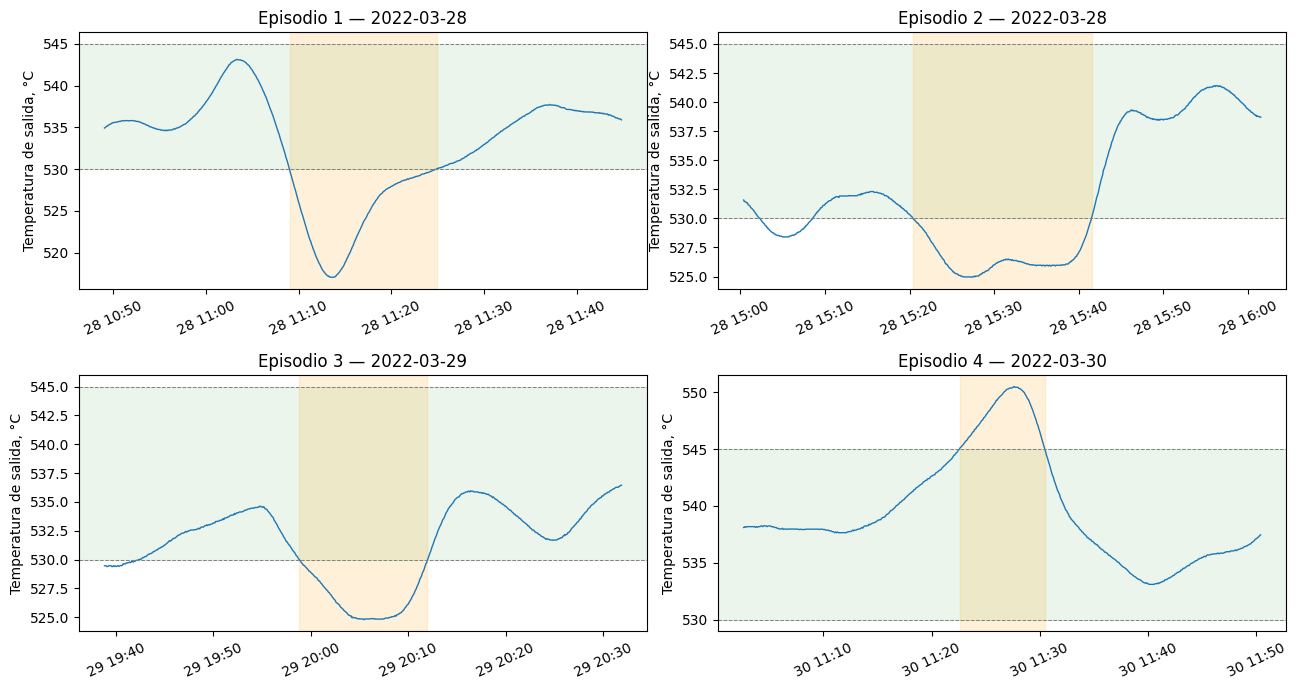

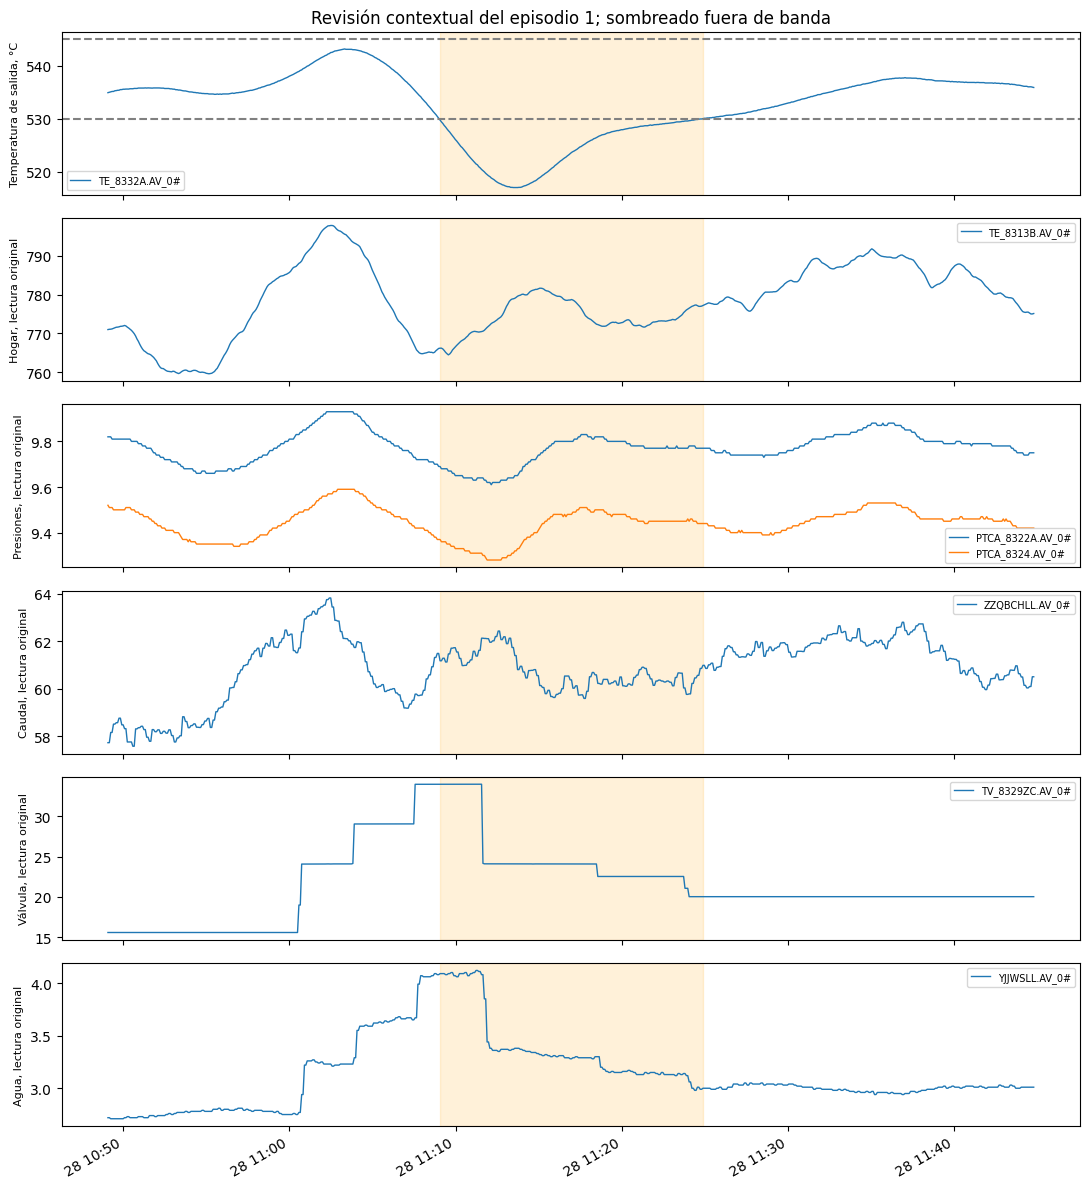

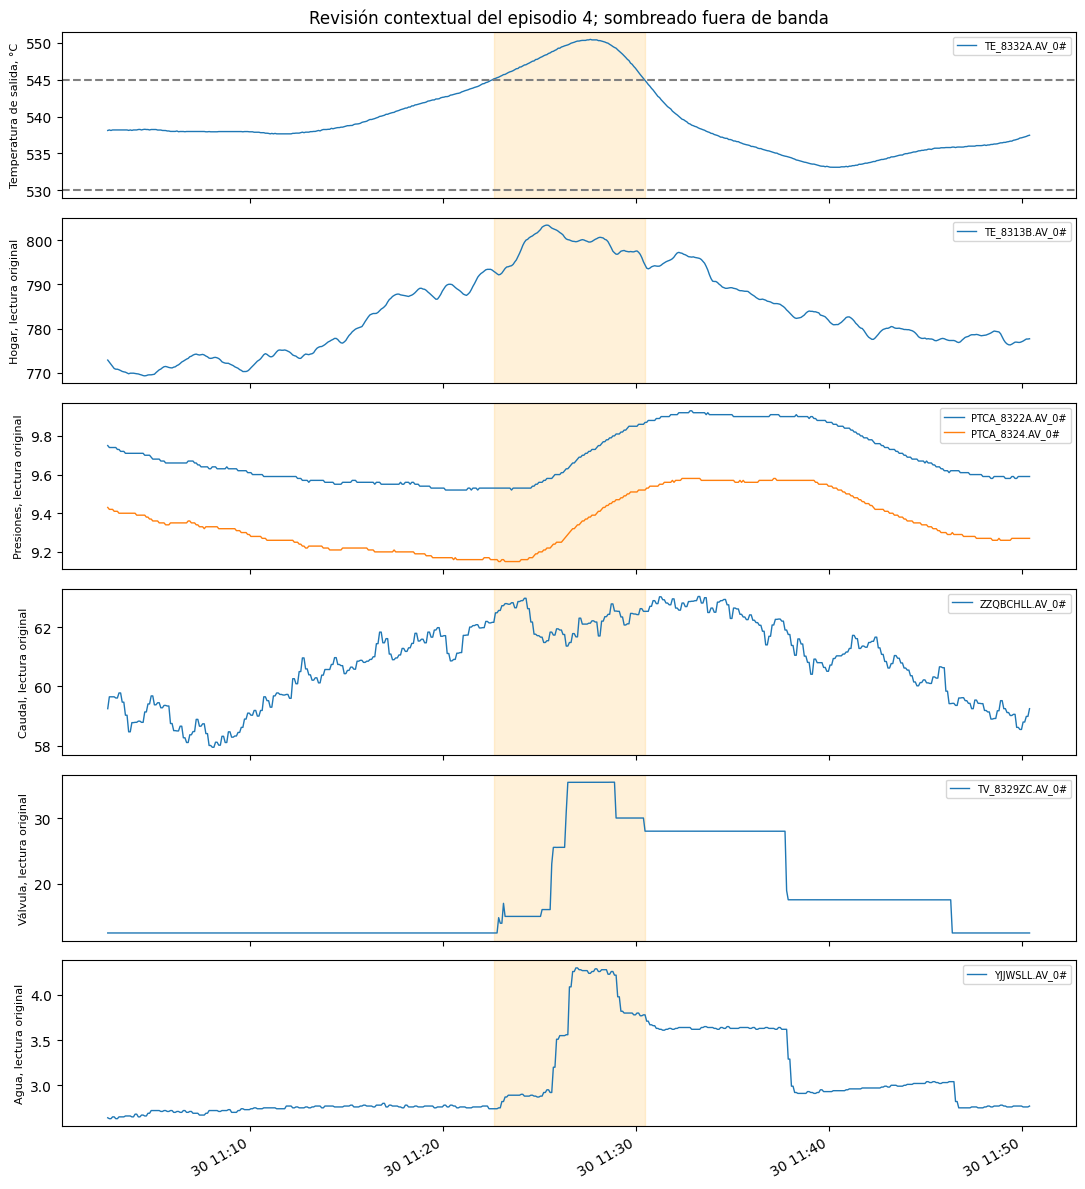

In [3]:
fig,axs=plt.subplots(2,2,figsize=(13,7))
for ax,(_,e) in zip(axs.flat,episodios.iterrows()):
    v=contextos.loc[contextos.episodio.eq(e.episodio)]
    ax.plot(v.date,v[TEMP],lw=1)
    ax.axhspan(530,545,color="green",alpha=.08)
    ax.axhline(530,color="gray",ls="--",lw=.7); ax.axhline(545,color="gray",ls="--",lw=.7)
    ax.axvspan(e.inicio,e.fin,color="orange",alpha=.15)
    ax.set_title(f"Episodio {int(e.episodio)} — {e.inicio.date()}"); ax.set_ylabel("Temperatura de salida, °C")
    ax.tick_params(axis="x",rotation=25)
fig.tight_layout(); fig.savefig(SALIDA/"cuatro_episodios_termicos.png",dpi=130); plt.show()
# Los dos extremos absolutos, con señales separadas para no mezclar unidades.
for caso in [int(controles.temperatura_extremo_C.idxmin())+1,int(controles.temperatura_extremo_C.idxmax())+1]:
    e=episodios.loc[episodios.episodio.eq(caso)].iloc[0]
    v=contextos.loc[contextos.episodio.eq(caso)]
    fig,axs=plt.subplots(6,1,figsize=(11,12),sharex=True)
    grupos=[([TEMP],"Temperatura de salida, °C"),(["TE_8313B.AV_0#"],"Hogar, lectura original"),
            (["PTCA_8322A.AV_0#","PTCA_8324.AV_0#"],"Presiones, lectura original"),
            (["ZZQBCHLL.AV_0#"],"Caudal, lectura original"),(["TV_8329ZC.AV_0#"],"Válvula, lectura original"),
            (["YJJWSLL.AV_0#"],"Agua, lectura original")]
    for ax,(senales,etiqueta) in zip(axs,grupos):
        for tag in senales: ax.plot(v.date,v[tag],label=tag,lw=1)
        ax.axvspan(e.inicio,e.fin,color="orange",alpha=.15)
        ax.set_ylabel(etiqueta,fontsize=8); ax.legend(fontsize=7,loc="best")
    axs[0].axhline(530,color="gray",ls="--"); axs[0].axhline(545,color="gray",ls="--")
    axs[0].set_title(f"Revisión contextual del episodio {caso}; sombreado fuera de banda")
    fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(SALIDA/f"contexto_extremo_{caso}.png",dpi=120); plt.show()

## Alcance sobre el entrenamiento

No se usa el error de Ridge para decidir validez ni se eliminan puntos difíciles para mejorar métricas. Una falla real del proceso puede aportar datos válidos al sensor virtual. Entrenar un detector solo con estados sanos requeriría otra definición y etiquetas de salud, que no tenemos. No se reentrena ni se cambian resultados de validación/evaluación.

Se contrasta el artefacto de quince entradas y las selecciones de cada pliegue. Se cuenta cuántas filas de la rejilla original de diez segundos del ajuste final caen en los episodios, sin modificarlas. Si posteriormente se confirmara un defecto **de temperatura**, habría que invalidar esa medición para los análisis que la usan, conservando el resto de la fila cuando siga siendo válido. Excluir un episodio por alcance operativo sería otra decisión explícita, no una limpieza de error.

In [4]:
entradas=pd.read_csv(RAIZ/"outputs/serie2_entradas_campeon.csv").entrada.tolist()
selecciones=pd.read_csv(RAIZ/"outputs/serie2_selecciones_por_pliegue.csv")
particiones=pd.read_csv(RAIZ/"outputs/serie2_particiones.csv")
final=particiones.iloc[-1]
ajuste_final=datos.date.between(pd.Timestamp(final.inicio_entrenamiento),pd.Timestamp(final.fin_entrenamiento)) & filas.fila_fuente.mod(2).eq(0)
exposicion={"temperatura_en_quince_finales":TEMP in entradas,
    "pliegues_que_seleccionaron_temperatura":selecciones.loc[selecciones.entrada.eq(TEMP),"particion"].tolist(),
    "filas_ajuste_final":int(ajuste_final.sum()),
    "filas_ajuste_final_en_episodios":int((ajuste_final & filas.episodio_revision.gt(0)).sum()),
    "filas_ajuste_final_extremo_mayor5C":int((ajuste_final & filas.extremo_mayor_5C).sum())}
assert ajuste_final.sum()==final.n_entrenamiento==34530
assert TEMP not in entradas
display(exposicion)
# Partición de conservación: ninguna fila se elimina; las revisadas se exportan además.
revision=datos.loc[filas.episodio_revision.gt(0)].copy()
revision.insert(0,"fila_fuente",revision.index)
revision["episodio_revision"]=filas.loc[revision.index,"episodio_revision"]
revision["motivo_revision"]="episodio fuera de banda que contiene distancia mayor de 5 C"
excluidas=datos.loc[filas.excluir].copy()
excluidas.insert(0,"fila_fuente",excluidas.index)
excluidas["motivo_exclusion"]=filas.loc[excluidas.index,"motivo_exclusion"]
assert len(excluidas)==0 and len(revision)==696 and len(filas)==len(datos)
filas.to_csv(SALIDA/"decision_por_fila.csv",index=False)
revision.to_csv(SALIDA/"filas_revisadas.csv",index=False)
excluidas.to_csv(SALIDA/"filas_excluidas.csv",index=False)
controles.to_csv(SALIDA/"episodios_revisados.csv",index=False)
comparaciones.to_csv(SALIDA/"comparaciones_contexto.csv",index=False)
contextos.to_csv(SALIDA/"contextos_completos.csv",index=False)
referencia_pasos.to_csv(SALIDA/"referencia_pasos_temperatura.csv")
assert all(hashlib.sha256((RAIZ/p).read_bytes()).hexdigest()==h for p,h in huellas.items())
verificacion={"filas_antes":len(datos),"filas_despues":len(filas),"filas_revisadas":len(revision),
    "lecturas_mayor5C":int(filas.extremo_mayor_5C.sum()),"filas_excluidas":len(excluidas),
    "episodios":len(episodios),"exposicion_modelo":exposicion,"huellas_protegidas":huellas,
    "decision":"conservar con marca; error no demostrado; no certifica sensor ni causalidad"}
(SALIDA/"verificacion.json").write_text(json.dumps(verificacion,indent=2,ensure_ascii=False),encoding="utf-8")
print("Conservación y huellas intactas:",len(filas),"filas;",len(huellas),"archivos protegidos.")

{'temperatura_en_quince_finales': False,
 'pliegues_que_seleccionaron_temperatura': ['Validación 3'],
 'filas_ajuste_final': 34530,
 'filas_ajuste_final_en_episodios': 348,
 'filas_ajuste_final_extremo_mayor5C': 87}

Conservación y huellas intactas: 86400 filas; 30 archivos protegidos.


## Decisión de calidad y cierre gerencial

**Se conservan los cuatro episodios completos, marcados para revisión; cero exclusiones.** La evidencia interna favorece tratarlos como desviaciones de proceso plausibles, con certeza moderada, sin confirmar causa ni exactitud instrumental:

- Las 173 lecturas a más de 5 °C pertenecen a cuatro episodios completos (696 lecturas). Incluyen tres descensos y un ascenso, todos con evolución gradual. No son cuatro errores de medición confirmados.
- En el mínimo de 517.05 °C, la mediana térmica pasa de 539.815 en diez minutos previos a 525.725 durante el episodio y luego a 532.845. Las temperaturas del hogar y ambos gases, presiones y caudal también bajan en sus medianas. El episodio completo cubre 950 s; la parte más allá de 10 °C cubre 225 s. La figura muestra incremento de la señal de agua/válvula antes del mínimo y posterior reducción, además de cambios previos del hogar: hipótesis de interacción térmica/control, sin aislar su causa ni confirmar que el tag sea posición real.
- En el máximo de 550.49 °C, la mediana pasa de 540.735 a 548.45 y después a 536.425. Hogar, gases, presiones y caudal suben durante el episodio; también suben las señales de agua/válvula. Es compatible con una respuesta de control frente al calentamiento, no prueba de que el agua provoque la desviación ni de independencia del sensor. Episodio completo de 470 s.
- Los otros dos descensos (mínimos 524.94 y 524.79 °C) también muestran medianas menores en hogar, gases, presiones y caudal, seguidas de recuperación térmica. Sus diferencias de 5.06 y 5.21 respecto de la banda ilustran que el umbral de revisión no es una frontera de validez.
- No hay ausencias, infinitos ni saltos de rejilla en los treinta sensores dentro de los cuatro contextos. Los mayores cambios térmicos por paso de cinco segundos en cada episodio son 0.38/0.22/0.23/0.35 °C; máximo global 0.38, percentil 99 de pasos 0.19. El mínimo incluye el paso más rápido del archivo, pero no existe velocidad certificada para declararlo imposible. Las figuras no muestran un salto vertical aislado que vuelva de inmediato. Una señal acondicionada o con deriva también puede ser suave.

La temperatura final no entra en la campeona final de quince, pero sí fue candidata en modelos de 29 y seleccionada en Validación 3. No se afirma que sea irrelevante para todo el trabajo. Se conservan las otras señales; las dependencias de compensación/medición siguen sin confirmarse. Borrar filas por esta banda mezclaría un criterio de operación con uno de validez y reduciría cobertura de transitorios sin evidencia de error.

**Certeza y límites:** la coherencia entre familias y continuidad apoyan conservar; no prueban ausencia de sesgo, deriva, falla común DCS o respuesta del controlador a un sensor incorrecto. Para una exclusión defendible se necesita bandera de calidad, rango certificado, contrastación instrumental independiente o registro de avería/calibración. Si se demuestra error, aplicar tratamiento por celda o episodio según causa, conservar original/cuarentena con motivo y reevaluar el entrenamiento con separación temporal. No establecer un rango válido aprendiendo de todo el futuro ni mejorar métricas filtrando evaluación.

Significado para el ingenio: los episodios podrían contener información útil para estudiar estabilidad térmica y para reconocer condiciones de operación menos frecuentes. Impacto observado: ninguna eliminación injustificada y trazabilidad de revisión; no ahorro ni exactitud física cuantificados. La prioridad siguiente es contrastar instrumentación/consignas y estudiar regulación bajo estos límites. Esta revisión no desarrolla las dos oportunidades ni convierte el detector en diagnóstico de falla.

## ¿Los avisos existentes cubren estos extremos?

Se cruza la revisión con las salidas ya calculadas de Isolation Forest y la regla térmica, sin reajustar. Se distingue candidatura puntual (`score > umbral`) de estado de aviso con persistencia/recuperación y de coincidencia en alguna parte del episodio. Que coincida un aviso no prueba su causa ni que la temperatura haya sido la contribución decisiva del modelo.

Isolation Forest tiene avisos activos en partes de los episodios 1 y 4; no en 2 y 3. En las cuatro lecturas extremas el score puntual está bajo el umbral; en la de 550.49 °C el aviso multivariable sigue activo por la regla de estado, no por superar el umbral en esa lectura. La regla térmica de doce lecturas consecutivas fuera de banda sí está activa en los cuatro extremos, tras su persistencia inicial. No son cuatro fallas etiquetadas: este cruce no estima recall ni precisión.

Si el objetivo incluye vigilar estas desviaciones térmicas, Isolation Forest solo es insuficiente en estos casos. El conjunto propuesto conserva regla específica de temperatura y detector multivariable: la primera responde a una condición operacional definida y el segundo a rareza conjunta. La banda bibliográfica requiere confirmación de operación antes de uso real. No se fuerza el umbral de IF para replicar la banda, ni se borra un transitorio porque no lo marque el modelo. Dato válido, desviación del proceso y candidatura estadística son conceptos distintos.

In [5]:
avisos=pd.read_csv(RAIZ/"outputs/anomalias/evaluacion_filas.csv",parse_dates=["date"],
    usecols=["date","score","umbral","candidata","aviso_multivariable","aviso_temperatura"])
cobertura=[]
for _,e in controles.iterrows():
    g=avisos.loc[avisos.date.between(e.inicio,e.fin_lectura)]
    punto=avisos.loc[avisos.date.eq(e.fecha_extremo)].iloc[0]
    cobertura.append({"episodio":int(e.episodio),"fecha_extremo":e.fecha_extremo,
        "temperatura_extremo_C":e.temperatura_extremo_C,"lecturas_episodio":len(g),
        "candidatas_IF_episodio":int(g.candidata.sum()),
        "lecturas_aviso_IF_episodio":int(g.aviso_multivariable.sum()),
        "lecturas_aviso_termico_episodio":int(g.aviso_temperatura.sum()),
        "score_extremo":punto.score,"umbral_extremo":punto.umbral,
        "candidata_IF_extremo":bool(punto.candidata),
        "aviso_IF_extremo":bool(punto.aviso_multivariable),
        "aviso_termico_extremo":bool(punto.aviso_temperatura)})
cobertura=pd.DataFrame(cobertura)
display(cobertura)
cobertura.to_csv(SALIDA/"cobertura_avisos_extremos.csv",index=False)
assert cobertura.lecturas_episodio.sum()==len(revision)
assert cobertura.aviso_termico_extremo.all() and not cobertura.candidata_IF_extremo.any()


,episodio,fecha_extremo,temperatura_extremo_C,lecturas_episodio,candidatas_IF_episodio,lecturas_aviso_IF_episodio,lecturas_aviso_termico_episodio,score_extremo,umbral_extremo,candidata_IF_extremo,aviso_IF_extremo,aviso_termico_extremo
0,1,2022-03-28 11:13:29,517.05,190,9,18,179,0.483878,0.520441,False,False,True
1,2,2022-03-28 15:27:19,524.94,254,0,0,243,0.476434,0.520441,False,False,True
2,3,2022-03-29 20:05:29,524.79,158,0,0,147,0.436678,0.548164,False,False,True
3,4,2022-03-30 11:27:39,550.49,94,12,54,83,0.535478,0.548164,False,True,True
